In [1]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path
from datetime import datetime

import sys
import json
import time
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from torch import nn

In [2]:
PROJECT_DIR = Path(
    r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca"
)

DATASET_DIR = (
    PROJECT_DIR
    / "dataset"
    / "raw"
    / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"

REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR = PROJECT_DIR / "models"

EXPERIMENTS_DIR = PROJECT_DIR / "experiments"

CACHE_DIR = (
    PROJECT_DIR
    / "dataset"
    / "cache"
    / "features_v1"
)

RUN_ID = "cv_cached_v1"

CV_REPORTS_DIR = (
    REPORTS_DIR / "cross_validation" / RUN_ID
)

CV_MODELS_DIR = (
    MODELS_DIR / "cross_validation" / RUN_ID
)

CV_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR / "cross_validation" / RUN_ID
)

for directory in [
    CACHE_DIR,
    CV_REPORTS_DIR,
    CV_MODELS_DIR,
    CV_EXPERIMENTS_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(PROJECT_DIR)
    )

In [3]:
from src.utils import (
    set_seed,
    get_device
)

from src.experiments import (
    save_json,
    save_predictions
)

from src.preprocessing import build_transforms

from src.data_generator import create_dataloader

from src.metrics import (
    calculate_class_weights,
    calculate_metrics,
    calculate_detailed_metrics
)

from src.model_factory import MODEL_REGISTRY

from src.feature_cache import (
    FEATURE_DIMS,
    calculate_sha256,
    create_feature_extractor,
    create_classifier,
    build_feature_cache,
    create_cached_dataset,
    release_memory
)

from src.cached_training import (
    create_cached_optimizer,
    train_cached_epoch,
    evaluate_cached,
    save_classifier_checkpoint
)

In [4]:
def load_json(filepath):

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as file:

        return json.load(file)


dataset_config = load_json(
    CONFIGS_DIR / "dataset_config.json"
)

training_config = load_json(
    CONFIGS_DIR / "training_config.json"
)

baseline_config = load_json(
    CONFIGS_DIR / "baseline_config.json"
)

SEED = training_config["seed"]

CLASS_MAPPING = dataset_config[
    "class_mapping"
]

NUM_CLASSES = len(CLASS_MAPPING)

ARCHITECTURES = training_config[
    "architectures"
]

DEVICE = get_device()

set_seed(SEED)

assert DEVICE.type == "cuda"

assert len(ARCHITECTURES) == 5

assert NUM_CLASSES == 5

print("GPU:", torch.cuda.get_device_name(0))
print("Device:", DEVICE)
print("Architectures:", ARCHITECTURES)

GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
Device: cuda
Architectures: ['mobilenet_v3_large', 'efficientnet_b0', 'resnet50', 'vit_b_16', 'swin_t']


In [5]:
optimized_path = (
    CONFIGS_DIR
    / "optimized_hyperparameters.json"
)

if optimized_path.exists():

    optimized_hyperparameters = load_json(
        optimized_path
    )

    hyperparameter_source = (
        "optimized_hyperparameters.json"
    )

else:

    optimized_hyperparameters = {}

    hyperparameter_source = (
        "baseline_with_available_hyperband"
    )

print(
    "Fuente:",
    hyperparameter_source
)

Fuente: optimized_hyperparameters.json


In [6]:
selected_hyperparameters = {}

for model_name in ARCHITECTURES:

    params = {
        "classifier_lr": baseline_config[
            "feature_extraction"
        ]["classifier_lr"],

        "weight_decay": baseline_config[
            "weight_decay"
        ],

        "dropout": baseline_config[
            "dropout"
        ],

        "source": "baseline_feature_extraction"
    }

    optimized = optimized_hyperparameters.get(
        model_name
    )

    if optimized is not None:

        fe_config = optimized[
            "training_config"
        ]["feature_extraction"]

        for key in [
            "classifier_lr",
            "weight_decay",
            "dropout"
        ]:

            params[key] = fe_config[key]

        if (
            optimized["source"] == "hyperband"
            and optimized["selected_stage"]
            == "feature_extraction"
        ):

            params["source"] = (
                "hyperband_feature_extraction"
            )

    selected_hyperparameters[
        model_name
    ] = params

display(
    pd.DataFrame(
        selected_hyperparameters
    ).T
)

,classifier_lr,weight_decay,dropout,source
mobilenet_v3_large,0.000766,0.000003,0.062398,hyperband_feature_extraction
efficientnet_b0,0.001,0.0001,0.2,baseline_feature_extraction
resnet50,0.001,0.0001,0.2,baseline_feature_extraction
vit_b_16,0.001,0.0001,0.2,baseline_feature_extraction
swin_t,0.001,0.0001,0.2,baseline_feature_extraction


In [7]:
cv_config = {

    "experiment_name": "cached_cross_validation",

    "run_id": RUN_ID,

    "seed": SEED,

    "architectures": ARCHITECTURES,

    "n_splits": 3,

    "folds": [1, 2, 3],

    "epochs": 3,

    "feature_caching": True,

    "pretrained": True,

    "freeze_backbone": True,

    "partial_finetuning": False,

    "augmentation": False,

    "classifier_batch_size": 32,

    "classifier_mixed_precision": False,

    "extraction_mixed_precision": True,

    "num_workers": 0,

    "extraction_batch_sizes": {

        "mobilenet_v3_large": 64,

        "efficientnet_b0": 64,

        "resnet50": 32,

        "vit_b_16": 16,

        "swin_t": 32

    },

    "optimizer": "AdamW",

    "loss": "WeightedCrossEntropyLoss",

    "selection_metric": "f1_macro",

    "scheduler": None,

    "test_reserved": True,

    "hyperparameters": selected_hyperparameters

}

config_path = (
    CONFIGS_DIR
    / "cross_validation_config.json"
)

if config_path.exists():

    assert load_json(config_path) == cv_config, (
        "La configuración experimental cambió."
    )

else:

    save_json(
        cv_config,
        config_path
    )

display(cv_config)

{'experiment_name': 'cached_cross_validation',
 'run_id': 'cv_cached_v1',
 'seed': 42,
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'n_splits': 3,
 'folds': [1, 2, 3],
 'epochs': 3,
 'feature_caching': True,
 'pretrained': True,
 'freeze_backbone': True,
 'partial_finetuning': False,
 'augmentation': False,
 'classifier_batch_size': 32,
 'classifier_mixed_precision': False,
 'extraction_mixed_precision': True,
 'num_workers': 0,
 'extraction_batch_sizes': {'mobilenet_v3_large': 64,
  'efficientnet_b0': 64,
  'resnet50': 32,
  'vit_b_16': 16,
  'swin_t': 32},
 'optimizer': 'AdamW',
 'loss': 'WeightedCrossEntropyLoss',
 'selection_metric': 'f1_macro',
 'scheduler': None,
 'test_reserved': True,
 'hyperparameters': {'mobilenet_v3_large': {'classifier_lr': 0.0007661100707771367,
   'weight_decay': 2.9380279387035354e-06,
   'dropout': 0.062397808134481064,
   'source': 'hyperband_feature_extraction'},
  'efficientnet_b0': {'classif

In [8]:
df_splits = pd.read_csv(
    REPORTS_DIR / "dataset_splits.csv"
)

df_development = df_splits[
    df_splits["split"] == "development"
].reset_index(drop=True)

df_test = df_splits[
    df_splits["split"] == "test"
].reset_index(drop=True)

assert len(df_development) == 18187

assert len(df_test) == 3210

assert df_development["filepath"].is_unique

assert set(
    df_development["sha256"]
).isdisjoint(
    df_test["sha256"]
)

assert set(
    df_development["fold"]
) == {1, 2, 3}

print("Development:", len(df_development))

print("Test reservado:", len(df_test))

display(
    pd.crosstab(
        df_development["class"],
        df_development["fold"]
    )
)

Development: 18187
Test reservado: 3210


fold,1,2,3
class,,,
bacterial_blight,308,308,308
brown_streak_disease,621,620,620
green_mottle,676,676,676
healthy,730,730,730
mosaic_disease,3728,3728,3728


In [9]:
tracked_files = [

    REPORTS_DIR / "dataset_splits.csv",

    CONFIGS_DIR / "dataset_config.json",

    CONFIGS_DIR / "preprocessing_config.json",

    CONFIGS_DIR / "model_config.json",

    CONFIGS_DIR / "baseline_config.json",

    CONFIGS_DIR / "cross_validation_config.json",

    PROJECT_DIR / "src" / "feature_cache.py",

    PROJECT_DIR / "src" / "cached_training.py",

    PROJECT_DIR / "src" / "model_factory.py",

    PROJECT_DIR / "src" / "preprocessing.py",

    PROJECT_DIR / "src" / "metrics.py",

    PROJECT_DIR / "src" / "dataset.py",

    PROJECT_DIR / "src" / "data_generator.py",

    PROJECT_DIR / "src" / "experiments.py",

    PROJECT_DIR / "src" / "utils.py"

]

if optimized_path.exists():

    tracked_files.append(
        optimized_path
    )

experiment_signature = {

    str(filepath.relative_to(PROJECT_DIR)):
        calculate_sha256(filepath)

    for filepath in tracked_files

}

signature_path = (
    CV_EXPERIMENTS_DIR
    / "experiment_signature.json"
)

if signature_path.exists():

    assert (
        load_json(signature_path)
        == experiment_signature
    ), "La firma experimental cambió."

else:

    save_json(
        experiment_signature,
        signature_path
    )

print(
    "Archivos verificados:",
    len(experiment_signature)
)

Archivos verificados: 16


In [10]:
_, eval_transform = build_transforms(
    CONFIGS_DIR
    / "preprocessing_config.json"
)

cache_metadata = {

    "preprocessing_hash": calculate_sha256(
        CONFIGS_DIR
        / "preprocessing_config.json"
    ),

    "model_factory_hash": calculate_sha256(
        PROJECT_DIR
        / "src"
        / "model_factory.py"
    ),

    "feature_cache_hash": calculate_sha256(
        PROJECT_DIR
        / "src"
        / "feature_cache.py"
    ),

    "torch_version": str(torch.__version__),

    "pretrained_weights": "ImageNet",

    "augmentation": False,

    "split": "development"

}

display(cache_metadata)

{'preprocessing_hash': 'da71c07df2c0f8fb334a42b9efd1a5ca68782fe2718937df8584c302fc9bacfc',
 'model_factory_hash': '0e3d3cd0b0f4a095dcfef87a090bda6ce89d077377aaf49d9f6dd33b76635757',
 'feature_cache_hash': '8134e70d233b1f09d017efccf89cf48ca18fb0043c15221a0f1730458a609bd1',
 'torch_version': '2.5.1+cu121',
 'pretrained_weights': 'ImageNet',
 'augmentation': False,
 'split': 'development'}

In [11]:
BENCHMARK_DIR = CACHE_DIR / "benchmark"

BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

df_benchmark = df_development.sample(
    n=512,
    random_state=SEED
).reset_index(drop=True)

benchmark_results = []

for model_name in ARCHITECTURES:

    print("\nBenchmark:", model_name)

    set_seed(SEED)

    release_memory()

    torch.cuda.reset_peak_memory_stats()

    cache = build_feature_cache(

        model_name=model_name,

        dataframe=df_benchmark,

        dataset_dir=DATASET_DIR,

        class_mapping=CLASS_MAPPING,

        eval_transform=eval_transform,

        cache_path=(
            BENCHMARK_DIR
            / f"{model_name}.pth"
        ),

        device=DEVICE,

        batch_size=cv_config[
            "extraction_batch_sizes"
        ][model_name],

        num_workers=0,

        seed=SEED,

        use_amp=True,

        cache_metadata=cache_metadata

    )

    seconds = cache["extraction_seconds"]

    images_per_second = (
        len(df_benchmark) / seconds
    )

    estimated_minutes = (
        len(df_development)
        / images_per_second
        / 60
    )

    benchmark_results.append({

        "architecture": model_name,

        "feature_dim": FEATURE_DIMS[
            model_name
        ],

        "benchmark_images": len(
            df_benchmark
        ),

        "seconds": seconds,

        "images_per_second": images_per_second,

        "estimated_full_minutes":
            estimated_minutes

    })

    del cache

    release_memory()

df_cache_benchmark = pd.DataFrame(
    benchmark_results
)

display(
    df_cache_benchmark.round(3)
)

df_cache_benchmark.to_csv(
    CV_REPORTS_DIR
    / "feature_cache_benchmark.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Tiempo total estimado de extracción:",
    round(
        df_cache_benchmark[
            "estimated_full_minutes"
        ].sum(),
        2
    ),
    "minutos"
)


Benchmark: mobilenet_v3_large
mobilenet_v3_large | torch.Size([512, 960]) | 0.10 min

Benchmark: efficientnet_b0
efficientnet_b0 | torch.Size([512, 1280]) | 0.08 min

Benchmark: resnet50
resnet50 | torch.Size([512, 2048]) | 0.09 min

Benchmark: vit_b_16
vit_b_16 | torch.Size([512, 768]) | 0.15 min

Benchmark: swin_t
swin_t | torch.Size([512, 768]) | 0.10 min


,architecture,feature_dim,benchmark_images,seconds,images_per_second,estimated_full_minutes
0,mobilenet_v3_large,960,512,5.841,87.660,3.458
1,efficientnet_b0,1280,512,4.715,108.584,2.792
2,resnet50,2048,512,5.375,95.252,3.182
3,vit_b_16,768,512,9.037,56.656,5.350
4,swin_t,768,512,6.216,82.371,3.680


Tiempo total estimado de extracción: 18.46 minutos


In [12]:
cache_results = []

cache_start = time.perf_counter()

for model_name in ARCHITECTURES:

    print("\n" + "=" * 60)

    print(
        "FEATURE CACHE:",
        model_name
    )

    print("=" * 60)

    set_seed(SEED)

    cache_path = (
        CACHE_DIR
        / f"{model_name}.pth"
    )

    cache = build_feature_cache(

        model_name=model_name,

        dataframe=df_development,

        dataset_dir=DATASET_DIR,

        class_mapping=CLASS_MAPPING,

        eval_transform=eval_transform,

        cache_path=cache_path,

        device=DEVICE,

        batch_size=cv_config[
            "extraction_batch_sizes"
        ][model_name],

        num_workers=cv_config[
            "num_workers"
        ],

        seed=SEED,

        use_amp=True,

        cache_metadata=cache_metadata

    )

    cache_results.append({

        "architecture": model_name,

        "num_images": len(
            cache["labels"]
        ),

        "feature_dim": cache[
            "features"
        ].shape[1],

        "extraction_minutes": (
            cache["extraction_seconds"]
            / 60
        ),

        "cache_size_mib": (
            cache_path.stat().st_size
            / (1024 ** 2)
        ),

        "cache_path": str(cache_path),

        "status": "success"

    })

    pd.DataFrame(
        cache_results
    ).to_csv(

        CV_REPORTS_DIR
        / "feature_cache_summary.csv",

        index=False,

        encoding="utf-8-sig"

    )

    del cache

    release_memory()

print(
    "Tiempo de esta ejecución:",
    round(
        (time.perf_counter() - cache_start)
        / 60,
        2
    ),
    "minutos"
)

display(
    pd.DataFrame(cache_results)
)


FEATURE CACHE: mobilenet_v3_large
  Batch 100/285
  Batch 200/285
mobilenet_v3_large | torch.Size([18187, 960]) | 3.15 min

FEATURE CACHE: efficientnet_b0
  Batch 100/285
  Batch 200/285
efficientnet_b0 | torch.Size([18187, 1280]) | 3.21 min

FEATURE CACHE: resnet50
  Batch 100/569
  Batch 200/569
  Batch 300/569
  Batch 400/569
  Batch 500/569
resnet50 | torch.Size([18187, 2048]) | 3.63 min

FEATURE CACHE: vit_b_16
  Batch 100/1137
  Batch 200/1137
  Batch 300/1137
  Batch 400/1137
  Batch 500/1137
  Batch 600/1137
  Batch 700/1137
  Batch 800/1137
  Batch 900/1137
  Batch 1000/1137
  Batch 1100/1137
vit_b_16 | torch.Size([18187, 768]) | 6.31 min

FEATURE CACHE: swin_t
  Batch 100/569
  Batch 200/569
  Batch 300/569
  Batch 400/569
  Batch 500/569
swin_t | torch.Size([18187, 768]) | 5.06 min
Tiempo de esta ejecución: 21.41 minutos


,architecture,num_images,feature_dim,extraction_minutes,cache_size_mib,cache_path,status
0,mobilenet_v3_large,18187,960,3.153955,67.409266,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,success
1,efficientnet_b0,18187,1280,3.210752,89.610176,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,success
2,resnet50,18187,2048,3.628100,142.892363,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,success
3,vit_b_16,18187,768,6.313651,54.088652,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,success
4,swin_t,18187,768,5.057361,54.088579,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,success


In [13]:
cache_verification = []

for model_name in ARCHITECTURES:

    cache = torch.load(

        CACHE_DIR
        / f"{model_name}.pth",

        map_location="cpu",

        weights_only=True

    )

    assert cache["features"].shape == (

        len(df_development),

        FEATURE_DIMS[model_name]

    )

    assert cache["features"].dtype == (
        torch.float32
    )

    assert torch.isfinite(
        cache["features"]
    ).all()

    assert cache["filepaths"] == (
        df_development["filepath"].tolist()
    )

    expected_labels = torch.tensor(

        df_development["class"]
        .map(CLASS_MAPPING)
        .tolist(),

        dtype=torch.long

    )

    assert torch.equal(

        cache["labels"],

        expected_labels

    )

    cache_verification.append({

        "architecture": model_name,

        "shape": str(
            tuple(cache["features"].shape)
        ),

        "dtype": str(
            cache["features"].dtype
        ),

        "valid": True

    })

    del cache

display(
    pd.DataFrame(cache_verification)
)

pd.DataFrame(
    cache_verification
).to_csv(

    CV_REPORTS_DIR
    / "feature_cache_verification.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,shape,dtype,valid
0,mobilenet_v3_large,"(18187, 960)",torch.float32,True
1,efficientnet_b0,"(18187, 1280)",torch.float32,True
2,resnet50,"(18187, 2048)",torch.float32,True
3,vit_b_16,"(18187, 768)",torch.float32,True
4,swin_t,"(18187, 768)",torch.float32,True


In [14]:
def run_cached_fold(
    model_name,
    cache,
    fold
):

    start = time.perf_counter()

    fold_seed = SEED + fold

    set_seed(fold_seed)

    params = selected_hyperparameters[
        model_name
    ]

    report_dir = (
        CV_REPORTS_DIR
        / model_name
        / f"fold_{fold}"
    )

    model_dir = (
        CV_MODELS_DIR
        / model_name
        / f"fold_{fold}"
    )

    report_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    model_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    result_path = (
        report_dir / "result.json"
    )

    checkpoint_path = (
        model_dir / "best_classifier.pth"
    )

    history_path = (
        report_dir / "history.csv"
    )

    predictions_path = (
        report_dir
        / "validation_predictions.csv"
    )

    if result_path.exists():

        result = load_json(result_path)

        required_files = [
            checkpoint_path,
            history_path,
            predictions_path
        ]

        if (
            result["status"] == "success"
            and all(
                p.exists()
                for p in required_files
            )
        ):

            print(
                f"Recuperado: {model_name} "
                f"| Fold {fold}"
            )

            return result

    train_indices = np.flatnonzero(
        df_development["fold"].to_numpy()
        != fold
    )

    val_indices = np.flatnonzero(
        df_development["fold"].to_numpy()
        == fold
    )

    df_train = df_development.iloc[
        train_indices
    ].reset_index(drop=True)

    df_val = df_development.iloc[
        val_indices
    ].reset_index(drop=True)

    assert len(
        np.intersect1d(
            train_indices,
            val_indices
        )
    ) == 0

    assert set(
        df_train["sha256"]
    ).isdisjoint(
        df_val["sha256"]
    )

    train_dataset = create_cached_dataset(
        cache,
        train_indices
    )

    val_dataset = create_cached_dataset(
        cache,
        val_indices
    )

    train_loader = create_dataloader(
        dataset=train_dataset,
        batch_size=cv_config[
            "classifier_batch_size"
        ],
        shuffle=True,
        num_workers=0,
        seed=fold_seed
    )

    val_loader = create_dataloader(
        dataset=val_dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0,
        seed=fold_seed
    )

    class_weights = calculate_class_weights(
        df_train,
        CLASS_MAPPING
    ).to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        reduction="sum"
    )

    classifier = create_classifier(
        model_name=model_name,
        num_classes=NUM_CLASSES,
        dropout=params["dropout"]
    ).to(DEVICE)

    optimizer = create_cached_optimizer(
        classifier=classifier,
        learning_rate=params[
            "classifier_lr"
        ],
        weight_decay=params[
            "weight_decay"
        ]
    )

    best_score = -1.0
    best_epoch = 0

    history = []

    for epoch in range(
        1,
        cv_config["epochs"] + 1
    ):

        train_metrics = train_cached_epoch(
            classifier=classifier,
            dataloader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=DEVICE,
            num_classes=NUM_CLASSES
        )

        val_metrics = evaluate_cached(
            classifier=classifier,
            dataloader=val_loader,
            criterion=criterion,
            device=DEVICE,
            num_classes=NUM_CLASSES
        )

        score = val_metrics["f1_macro"]

        improved = score > best_score

        if improved:

            best_score = score
            best_epoch = epoch

            save_classifier_checkpoint(
                classifier=classifier,
                filepath=checkpoint_path,
                metadata={
                    "architecture": model_name,
                    "fold": fold,
                    "epoch": epoch,
                    "f1_macro": float(score),
                    "class_mapping": CLASS_MAPPING,
                    "dropout": params["dropout"],
                    "hyperparameters": params,
                    "seed": fold_seed,
                    "feature_dim": FEATURE_DIMS[
                        model_name
                    ],
                    "class_weights":
                        class_weights.cpu().tolist(),
                    "training_mode":
                        "cached_feature_extraction"
                }
            )

        history.append({

            "epoch": epoch,

            **{
                f"train_{key}": value
                for key, value
                in train_metrics.items()
            },

            **{
                f"val_{key}": value
                for key, value
                in val_metrics.items()
            },

            "is_best": improved

        })

        print(
            f"{model_name} | "
            f"Fold {fold} | "
            f"Epoch {epoch} | "
            f"Train F1: "
            f"{train_metrics['f1_macro']:.4f} | "
            f"Val F1: {score:.4f}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    classifier.load_state_dict(
        checkpoint["classifier_state_dict"],
        strict=True
    )

    final_metrics, predictions = evaluate_cached(
        classifier=classifier,
        dataloader=val_loader,
        criterion=criterion,
        device=DEVICE,
        num_classes=NUM_CLASSES,
        return_predictions=True
    )

    assert np.isclose(
        final_metrics["f1_macro"],
        best_score,
        atol=1e-6
    )

    save_predictions(
        dataframe=df_val,
        predictions=predictions,
        class_mapping=CLASS_MAPPING,
        filepath=predictions_path
    )

    detailed_metrics = calculate_detailed_metrics(
        predictions["y_true"],
        predictions["y_pred"],
        CLASS_MAPPING
    )

    save_json(
        detailed_metrics,
        report_dir / "detailed_metrics.json"
    )

    pd.DataFrame(history).to_csv(
        history_path,
        index=False,
        encoding="utf-8-sig"
    )

    total_seconds = (
        time.perf_counter() - start
    )

    result = {

        "architecture": model_name,

        "family": MODEL_REGISTRY[
            model_name
        ]["family"],

        "fold": fold,

        "best_epoch": best_epoch,

        "epochs_completed": len(history),

        "train_images": len(df_train),

        "validation_images": len(df_val),

        "hyperparameter_source":
            params["source"],

        **final_metrics,

        "total_seconds": total_seconds,

        "total_minutes": total_seconds / 60,

        "status": "success"

    }

    save_json(
        result,
        result_path
    )

    del classifier
    del optimizer
    del criterion
    del train_loader
    del val_loader
    del train_dataset
    del val_dataset

    release_memory()

    return result


In [15]:
pilot_model = "mobilenet_v3_large"

pilot_cache = torch.load(

    CACHE_DIR
    / f"{pilot_model}.pth",

    map_location="cpu",

    weights_only=True

)

pilot_result = run_cached_fold(

    model_name=pilot_model,

    cache=pilot_cache,

    fold=1

)

display(
    pd.DataFrame([pilot_result])
)

del pilot_cache

release_memory()

mobilenet_v3_large | Fold 1 | Epoch 1 | Train F1: 0.5187 | Val F1: 0.5234
mobilenet_v3_large | Fold 1 | Epoch 2 | Train F1: 0.5851 | Val F1: 0.5863
mobilenet_v3_large | Fold 1 | Epoch 3 | Train F1: 0.6147 | Val F1: 0.5526


,architecture,family,fold,best_epoch,epochs_completed,train_images,validation_images,hyperparameter_source,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples,total_seconds,total_minutes,status
0,mobilenet_v3_large,CNN,1,2,3,12124,6063,hyperband_feature_extraction,0.720106,0.571428,0.613133,0.586278,0.732977,0.613133,0.988865,0.111733,6063,5.180306,0.086338,success


In [16]:
pilot_history = pd.read_csv(

    CV_REPORTS_DIR

    / "mobilenet_v3_large"

    / "fold_1"

    / "history.csv"

)

display(

    pilot_history[[

        "epoch",

        "train_loss",

        "train_f1_macro",

        "val_loss",

        "val_f1_macro",

        "train_optimizer_steps",

        "train_seconds",

        "val_seconds"

    ]].round(4)

)

assert len(pilot_history) == 3

assert (

    pilot_history[
        "train_optimizer_steps"
    ] == 379

).all()

print(

    "Tiempo total del piloto:",

    round(
        pilot_result["total_seconds"],
        2
    ),

    "segundos"

)

,epoch,train_loss,train_f1_macro,val_loss,val_f1_macro,train_optimizer_steps,train_seconds,val_seconds
0,1,1.0784,0.5187,1.0247,0.5234,379,1.6254,0.1286
1,2,0.9138,0.5851,0.9889,0.5863,379,1.0751,0.1368
2,3,0.8509,0.6147,0.9691,0.5526,379,1.1706,0.1204


Tiempo total del piloto: 5.18 segundos


In [17]:
cv_results = []

cv_errors = []

cv_start = time.perf_counter()

for model_name in ARCHITECTURES:

    print("\n" + "=" * 65)

    print("CROSS-VALIDATION:", model_name)

    print("=" * 65)

    cache = None

    try:

        cache = torch.load(

            CACHE_DIR
            / f"{model_name}.pth",

            map_location="cpu",

            weights_only=True

        )

        for fold in cv_config["folds"]:

            result = run_cached_fold(

                model_name=model_name,

                cache=cache,

                fold=fold

            )

            cv_results.append(result)

            pd.DataFrame(
                cv_results
            ).to_csv(

                CV_REPORTS_DIR
                / "cross_validation_results.csv",

                index=False,

                encoding="utf-8-sig"

            )

    except KeyboardInterrupt:

        print("Ejecución interrumpida.")

        break

    except Exception as error:

        cv_errors.append({

            "architecture": model_name,

            "error": str(error)

        })

        print("Error:", error)

        break

    finally:

        del cache

        release_memory()

        save_json(

            cv_errors,

            CV_EXPERIMENTS_DIR
            / "cross_validation_errors.json"

        )

print(

    "Tiempo de esta ejecución:",

    round(
        (time.perf_counter() - cv_start)
        / 60,
        2
    ),

    "minutos"

)

display(
    pd.DataFrame(cv_results)
)


CROSS-VALIDATION: mobilenet_v3_large
Recuperado: mobilenet_v3_large | Fold 1
mobilenet_v3_large | Fold 2 | Epoch 1 | Train F1: 0.5181 | Val F1: 0.5164
mobilenet_v3_large | Fold 2 | Epoch 2 | Train F1: 0.5831 | Val F1: 0.5858
mobilenet_v3_large | Fold 2 | Epoch 3 | Train F1: 0.6190 | Val F1: 0.5864
mobilenet_v3_large | Fold 3 | Epoch 1 | Train F1: 0.5171 | Val F1: 0.5527
mobilenet_v3_large | Fold 3 | Epoch 2 | Train F1: 0.5891 | Val F1: 0.5815
mobilenet_v3_large | Fold 3 | Epoch 3 | Train F1: 0.6117 | Val F1: 0.5640

CROSS-VALIDATION: efficientnet_b0
efficientnet_b0 | Fold 1 | Epoch 1 | Train F1: 0.5047 | Val F1: 0.5252
efficientnet_b0 | Fold 1 | Epoch 2 | Train F1: 0.5712 | Val F1: 0.5774
efficientnet_b0 | Fold 1 | Epoch 3 | Train F1: 0.5869 | Val F1: 0.5868
efficientnet_b0 | Fold 2 | Epoch 1 | Train F1: 0.4998 | Val F1: 0.5570
efficientnet_b0 | Fold 2 | Epoch 2 | Train F1: 0.5680 | Val F1: 0.5916
efficientnet_b0 | Fold 2 | Epoch 3 | Train F1: 0.5884 | Val F1: 0.5876
efficientnet_b0 |

,architecture,family,fold,best_epoch,epochs_completed,train_images,validation_images,hyperparameter_source,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples,total_seconds,total_minutes,status
0,mobilenet_v3_large,CNN,1,2,3,12124,6063,hyperband_feature_extraction,0.720106,0.571428,0.613133,0.586278,0.732977,0.613133,0.988865,0.111733,6063,5.180306,0.086338,success
1,mobilenet_v3_large,CNN,2,3,3,12125,6062,hyperband_feature_extraction,0.709832,0.557680,0.635839,0.586390,0.726308,0.635839,0.947854,0.120457,6062,5.048350,0.084139,success
2,mobilenet_v3_large,CNN,3,2,3,12125,6062,hyperband_feature_extraction,0.700264,0.567190,0.622324,0.581547,0.717744,0.622324,0.976545,0.117448,6062,4.368447,0.072807,success
3,efficientnet_b0,CNN,1,3,3,12124,6063,baseline_feature_extraction,0.718786,0.571231,0.629405,0.586798,0.732368,0.629405,0.962638,0.144130,6063,3.443452,0.057391,success
4,efficientnet_b0,CNN,2,2,3,12125,6062,baseline_feature_extraction,0.717090,0.568426,0.631650,0.591637,0.730211,0.631650,0.966339,0.154811,6062,4.135846,0.068931,success
5,efficientnet_b0,CNN,3,2,3,12125,6062,baseline_feature_extraction,0.700264,0.557483,0.624900,0.582407,0.717841,0.624900,0.958164,0.187901,6062,4.148617,0.069144,success
6,resnet50,CNN,1,3,3,12124,6063,baseline_feature_extraction,0.698664,0.555364,0.623847,0.573728,0.717651,0.623847,0.993164,0.194270,6063,4.296111,0.071602,success
7,resnet50,CNN,2,3,3,12125,6062,baseline_feature_extraction,0.694985,0.547111,0.624220,0.575484,0.714699,0.624220,0.979607,0.229953,6062,4.308541,0.071809,success
8,resnet50,CNN,3,3,3,12125,6062,baseline_feature_extraction,0.703563,0.567128,0.624034,0.587358,0.720873,0.624034,0.976302,0.188226,6062,4.254253,0.070904,success
9,vit_b_16,Transformer,1,2,3,12124,6063,baseline_feature_extraction,0.725878,0.564980,0.620019,0.585846,0.736963,0.620019,0.982948,0.133997,6063,3.637308,0.060622,success


In [18]:
df_cv_results = pd.read_csv(

    CV_REPORTS_DIR

    / "cross_validation_results.csv"

)

assert len(df_cv_results) == 15

assert not df_cv_results.duplicated(

    subset=[
        "architecture",
        "fold"
    ]

).any()

display(

    df_cv_results[[

        "architecture",

        "fold",

        "accuracy",

        "precision_macro",

        "recall_macro",

        "f1_macro",

        "best_epoch",

        "total_minutes"

    ]].round(4)

)

,architecture,fold,accuracy,precision_macro,recall_macro,f1_macro,best_epoch,total_minutes
0,mobilenet_v3_large,1,0.7201,0.5714,0.6131,0.5863,2,0.0863
1,mobilenet_v3_large,2,0.7098,0.5577,0.6358,0.5864,3,0.0841
2,mobilenet_v3_large,3,0.7003,0.5672,0.6223,0.5815,2,0.0728
3,efficientnet_b0,1,0.7188,0.5712,0.6294,0.5868,3,0.0574
4,efficientnet_b0,2,0.7171,0.5684,0.6317,0.5916,2,0.0689
5,efficientnet_b0,3,0.7003,0.5575,0.6249,0.5824,2,0.0691
6,resnet50,1,0.6987,0.5554,0.6238,0.5737,3,0.0716
7,resnet50,2,0.6950,0.5471,0.6242,0.5755,3,0.0718
8,resnet50,3,0.7036,0.5671,0.6240,0.5874,3,0.0709
9,vit_b_16,1,0.7259,0.5650,0.6200,0.5858,2,0.0606


In [19]:
df_cv_summary = (

    df_cv_results

    .groupby(
        ["architecture", "family"]
    )

    .agg(

        accuracy_mean=(
            "accuracy", "mean"
        ),

        accuracy_std=(
            "accuracy", "std"
        ),

        precision_macro_mean=(
            "precision_macro", "mean"
        ),

        recall_macro_mean=(
            "recall_macro", "mean"
        ),

        f1_macro_mean=(
            "f1_macro", "mean"
        ),

        f1_macro_std=(
            "f1_macro", "std"
        ),

        f1_macro_min=(
            "f1_macro", "min"
        ),

        f1_macro_max=(
            "f1_macro", "max"
        ),

        total_minutes=(
            "total_minutes", "sum"
        ),

        folds_completed=(
            "fold", "count"
        )

    )

    .reset_index()

    .sort_values(

        "f1_macro_mean",

        ascending=False

    )

)

df_cv_summary.insert(

    0,

    "rank",

    range(
        1,
        len(df_cv_summary) + 1
    )

)

display(
    df_cv_summary.round(4)
)

df_cv_summary.to_csv(

    CV_REPORTS_DIR

    / "cross_validation_summary.csv",

    index=False,

    encoding="utf-8-sig"

)

,rank,architecture,family,accuracy_mean,accuracy_std,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std,f1_macro_min,f1_macro_max,total_minutes,folds_completed
3,1,swin_t,Transformer,0.7384,0.0108,0.5979,0.6592,0.6212,0.0112,0.6084,0.6291,0.1781,3
0,2,efficientnet_b0,CNN,0.7120,0.0102,0.5657,0.6287,0.5869,0.0046,0.5824,0.5916,0.1955,3
1,3,mobilenet_v3_large,CNN,0.7101,0.0099,0.5654,0.6238,0.5847,0.0028,0.5815,0.5864,0.2433,3
4,4,vit_b_16,Transformer,0.7014,0.0230,0.5579,0.6271,0.5816,0.0038,0.5783,0.5858,0.1789,3
2,5,resnet50,CNN,0.6991,0.0043,0.5565,0.6240,0.5789,0.0074,0.5737,0.5874,0.2143,3


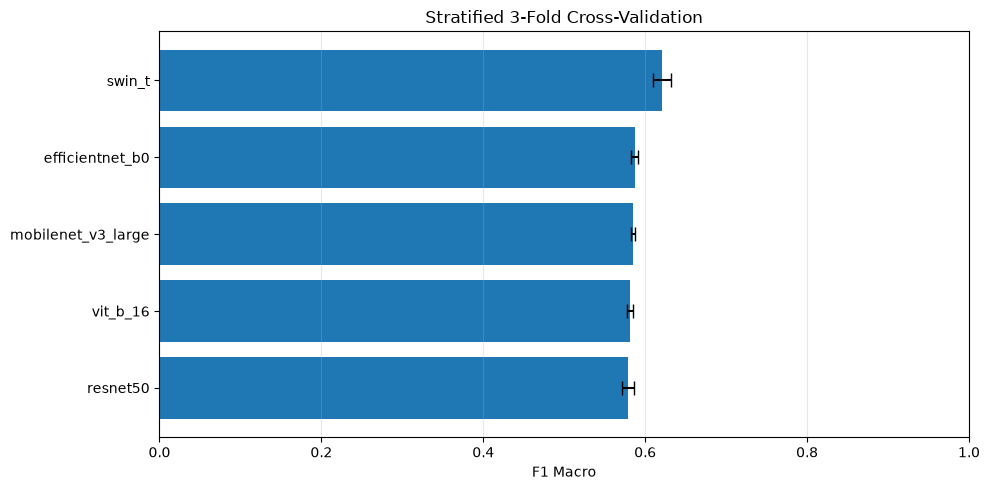

In [20]:
plt.figure(figsize=(10, 5))

plt.barh(

    df_cv_summary["architecture"],

    df_cv_summary["f1_macro_mean"],

    xerr=df_cv_summary["f1_macro_std"],

    capsize=5

)

plt.gca().invert_yaxis()

plt.xlabel("F1 Macro")

plt.title(
    "Stratified 3-Fold Cross-Validation"
)

plt.xlim(0, 1)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(

    CV_REPORTS_DIR

    / "cross_validation_f1_macro.png",

    dpi=200

)

plt.show()

In [21]:
oof_results = []

for model_name in ARCHITECTURES:

    fold_predictions = []

    for fold in [1, 2, 3]:

        filepath = (

            CV_REPORTS_DIR

            / model_name

            / f"fold_{fold}"

            / "validation_predictions.csv"

        )

        df_predictions = pd.read_csv(
            filepath
        )

        assert (
            df_predictions["fold"] == fold
        ).all()

        fold_predictions.append(
            df_predictions
        )

    df_oof = pd.concat(

        fold_predictions,

        ignore_index=True

    )

    assert len(df_oof) == len(
        df_development
    )

    assert df_oof["filepath"].is_unique

    assert set(
        df_oof["filepath"]
    ) == set(
        df_development["filepath"]
    )

    expected_labels = (

        df_oof["class"]

        .map(CLASS_MAPPING)

        .to_numpy()

    )

    assert np.array_equal(

        df_oof["y_true"].to_numpy(),

        expected_labels

    )

    probability_columns = [

        f"prob_{class_name}"

        for class_name, class_id in sorted(

            CLASS_MAPPING.items(),

            key=lambda item: item[1]

        )

    ]

    probabilities = df_oof[
        probability_columns
    ].to_numpy()

    assert np.isfinite(probabilities).all()

    assert (probabilities >= 0).all()

    assert np.allclose(

        probabilities.sum(axis=1),

        1.0,

        atol=1e-5

    )

    assert np.array_equal(

        probabilities.argmax(axis=1),

        df_oof["y_pred"].to_numpy()

    )

    df_oof = df_oof.sort_values(
        "filepath"
    ).reset_index(drop=True)

    df_oof.to_csv(

        CV_REPORTS_DIR

        / model_name

        / "oof_predictions.csv",

        index=False,

        encoding="utf-8-sig"

    )

    metrics = calculate_metrics(

        df_oof["y_true"],

        df_oof["y_pred"],

        NUM_CLASSES

    )

    oof_results.append({

        "architecture": model_name,

        "num_predictions": len(df_oof),

        **metrics

    })

df_oof_results = pd.DataFrame(
    oof_results
)

display(
    df_oof_results.round(4)
)

df_oof_results.to_csv(

    CV_REPORTS_DIR

    / "oof_results.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,num_predictions,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy
0,mobilenet_v3_large,18187,0.7101,0.5583,0.6238,0.5843,0.7256,0.6238
1,efficientnet_b0,18187,0.7120,0.5601,0.6286,0.5866,0.7267,0.6286
2,resnet50,18187,0.6991,0.5525,0.6240,0.5787,0.7177,0.6240
3,vit_b_16,18187,0.7014,0.5551,0.6271,0.5818,0.7197,0.6271
4,swin_t,18187,0.7384,0.5933,0.6592,0.6206,0.7510,0.6592


In [22]:
final_training_config = {

    "seed": SEED,

    "architectures": ARCHITECTURES,

    "training_mode":
        "cached_feature_extraction",

    "feature_cache_dir": str(
        CACHE_DIR.relative_to(PROJECT_DIR)
    ),

    "epochs": 3,

    "batch_size": 32,

    "mixed_precision": False,

    "optimizer": "AdamW",

    "scheduler": None,

    "augmentation": False,

    "class_weighting": True,

    "training_split": "development",

    "num_training_images": len(
        df_development
    ),

    "hyperparameters":
        selected_hyperparameters,

    "cross_validation_run_id": RUN_ID,

    "test_reserved": True

}

save_json(

    final_training_config,

    CONFIGS_DIR

    / "final_training_config.json"

)

print(
    "Configuración de Final Training guardada."
)

Configuración de Final Training guardada.


In [23]:
assert len(df_cv_results) == 15

assert len(df_cv_summary) == 5

assert len(df_oof_results) == 5

assert (

    df_cv_summary["folds_completed"] == 3

).all()

assert (

    df_cv_results["epochs_completed"] == 3

).all()

assert (

    df_cv_results["status"] == "success"

).all()

assert (

    df_oof_results["num_predictions"]

    == len(df_development)

).all()

assert cv_config["test_reserved"]

assert not cv_config["partial_finetuning"]

assert cv_config["feature_caching"]

assert (

    df_cv_summary["family"] == "CNN"

).sum() == 3

assert (

    df_cv_summary["family"] == "Transformer"

).sum() == 2

print(
    "Validación cruzada verificada correctamente."
)

Validación cruzada verificada correctamente.


In [24]:
df_cache_summary = pd.read_csv(

    CV_REPORTS_DIR

    / "feature_cache_summary.csv"

)

best_model = df_cv_summary.iloc[0]

cv_summary = {

    "phase": "phase_2_part_6",

    "experiment": "stratified_cross_validation",

    "run_id": RUN_ID,

    "status": "completed",

    "architectures": 5,

    "cnn_architectures": 3,

    "transformer_architectures": 2,

    "n_splits": 3,

    "completed_trainings": 15,

    "total_training_epochs": 45,

    "feature_caching": True,

    "partial_finetuning": False,

    "augmentation": False,

    "development_images": len(
        df_development
    ),

    "test_images_reserved": len(
        df_test
    ),

    "test_used": False,

    "best_architecture": str(
        best_model["architecture"]
    ),

    "best_mean_f1_macro": float(
        best_model["f1_macro_mean"]
    ),

    "best_std_f1_macro": float(
        best_model["f1_macro_std"]
    ),

    "feature_extraction_minutes": float(

        df_cache_summary[
            "extraction_minutes"
        ].sum()

    ),

    "classifier_training_minutes": float(

        df_cv_results[
            "total_minutes"
        ].sum()

    ),

    "cache_size_mib": float(

        df_cache_summary[
            "cache_size_mib"
        ].sum()

    ),

    "oof_predictions_generated": True,

    "final_training_config_generated": True,

    "nested_cross_validation": False,

    "timestamp": datetime.now().isoformat()

}

cv_summary["total_compute_minutes"] = (

    cv_summary["feature_extraction_minutes"]

    + cv_summary["classifier_training_minutes"]

)

save_json(

    cv_summary,

    CV_EXPERIMENTS_DIR

    / "cross_validation_summary.json"

)

display(cv_summary)

print("=" * 65)

print("FASE 2 - PARTE 6 COMPLETADA")

print("=" * 65)

release_memory()

{'phase': 'phase_2_part_6',
 'experiment': 'stratified_cross_validation',
 'run_id': 'cv_cached_v1',
 'status': 'completed',
 'architectures': 5,
 'cnn_architectures': 3,
 'transformer_architectures': 2,
 'n_splits': 3,
 'completed_trainings': 15,
 'total_training_epochs': 45,
 'feature_caching': True,
 'partial_finetuning': False,
 'augmentation': False,
 'development_images': 18187,
 'test_images_reserved': 3210,
 'test_used': False,
 'best_architecture': 'swin_t',
 'best_mean_f1_macro': 0.6212140800803966,
 'best_std_f1_macro': 0.01118515171664511,
 'feature_extraction_minutes': 21.363818895000016,
 'classifier_training_minutes': 1.0101243233333055,
 'cache_size_mib': 408.0890350341797,
 'oof_predictions_generated': True,
 'final_training_config_generated': True,
 'nested_cross_validation': False,
 'timestamp': '2026-11-26T01:45:47.855719',
 'total_compute_minutes': 22.37394321833332}

FASE 2 - PARTE 6 COMPLETADA
